In [1]:
import numpy as np                                     # arrays of numbers
import matplotlib.pyplot as plt                        # draw pictures and charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # nn = "neural network": layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split data into train / validation / test
from sklearn.datasets import load_digits               # the handwritten digits pictures

def show(grid, title):                                 # draw a small grid with its numbers on it
    grid = np.array(grid)
    plt.imshow(grid, cmap="gray_r")                    # big number = dark (ink)
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            plt.text(c, r, f"{grid[r, c]:g}", ha="center", va="center", color="tab:orange")
    plt.title(title)
    plt.axis("off")
    plt.show()

torch.Size([6, 6])


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_22004\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


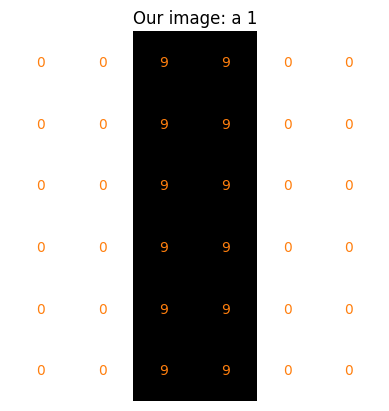

In [2]:
image = torch.tensor([[0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0]], dtype=torch.float32)

print(image.shape)          # 6 rows, 6 columns
show(image, "Our image: a 1")

C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_22004\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


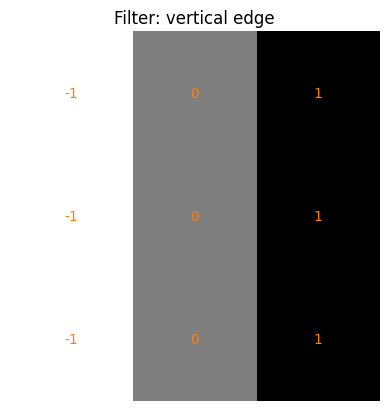

In [3]:
filter_v = torch.tensor([[-1, 0, 1],
                         [-1, 0, 1],
                         [-1, 0, 1]], dtype=torch.float32)   # v = vertical edge
show(filter_v, "Filter: vertical edge")

torch.Size([3, 3])


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_22004\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


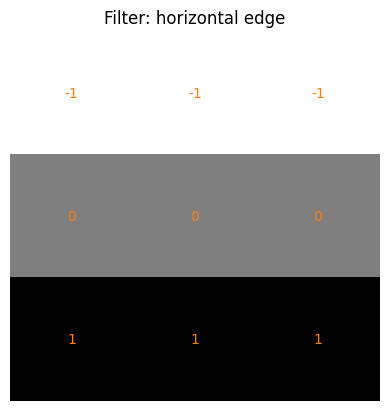

In [4]:
filter_h = torch.tensor([[-1,-1,-1],
                         [ 0, 0, 0],
                         [ 1, 1, 1]], dtype=torch.float32)  
print(filter_h.shape)        # 3 rows, 3 columns
show(filter_h, "Filter: horizontal edge")

In [5]:
window = image[0:3, 1:4]               # rows 0,1,2 and columns 1,2,3
print(window)
print(window * filter_v)               # 2. multiply matching numbers (-0 is just 0)
print((window * filter_v).sum())       # 3. add → 27

tensor([[0., 9., 9.],
        [0., 9., 9.],
        [0., 9., 9.]])
tensor([[-0., 0., 9.],
        [-0., 0., 9.],
        [-0., 0., 9.]])
tensor(27.)


tensor([[ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.]])


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_22004\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


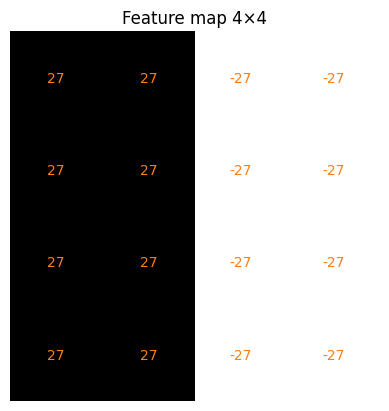

In [6]:
size = 6 - 3 + 1                                   # 4 windows across, 4 down
feature_map = torch.zeros(size, size)

for r in range(size):                              # slide down
    for c in range(size):                          # slide right
        window = image[r:r+3, c:c+3]               # 1. place
        feature_map[r, c] = (window * filter_v).sum()   # 2. multiply + 3. add

print(feature_map)
show(feature_map, "Feature map 4×4")

In [7]:
window = image[0:3, 2:5]
print((window * filter_v).sum())       # −27: ink ends here

tensor(-27.)


In [12]:
x = image.reshape(1, 1, 6, 6)                       # (pictures, channels, height, width)

conv = nn.Conv2d(1, 1, 3, bias=False)               # 1 channel in, 1 filter, 3×3

with torch.no_grad():                               # we set the numbers ourselves, no training
    conv.weight[:] = filter_v.reshape(1, 1, 3, 3)

out_conv = conv(x)
print(out_conv.shape)                               # (1, 1, 4, 4) → 4×4
print(out_conv[0, 0]) 

torch.Size([1, 1, 4, 4])
tensor([[ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.]], grad_fn=<SelectBackward0>)


In [9]:
out_relu = nn.ReLU()(out_conv)
print(out_relu[0, 0])  

tensor([[27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.]], grad_fn=<SelectBackward0>)


In [10]:
print(nn.ReLU()(torch.tensor([-5., 3., -2., 8.])))   # [0, 3, 0, 8]

tensor([0., 3., 0., 8.])


torch.Size([1, 1, 2, 2])
tensor([[27.,  0.],
        [27.,  0.]], grad_fn=<SelectBackward0>)


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_22004\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


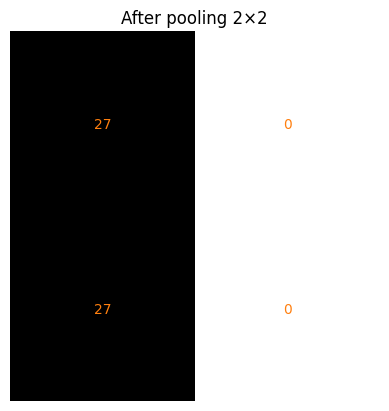

In [13]:
out_pool = nn.MaxPool2d(2)(out_relu)
print(out_pool.shape)                               # (1, 1, 2, 2)
print(out_pool[0, 0])                               # 27 0 / 27 0
show(out_pool[0, 0].detach(), "After pooling 2×2")